[1/5] Carregando a base de dados...
Total de Transações: 284,807
Transações Normais: 284,315 (99.83%)
Fraudes Confirmadas: 492 (0.173%)

[2/5] Realizando Engenharia de Features e Pré-processamento...
Base de Treino: 227,845 registros (394 fraudes)
Base de Teste:  56,962 registros (98 fraudes)

[3/5] Treinando os 3 modelos com pesos de balanceamento...
  -> Treinando Regressão Logística (Baseline)...
  -> Treinando Random Forest...
  -> Treinando XGBoost...

[4/5] Avaliando métricas e curvas de performance...


,Modelo,Recall (Detecção de Fraude),Precisão (Acertos),F1-Score,PR-AUC,ROC-AUC
0,Regressão Logística (Baseline),91.84%,6.01%,0.1129,0.7113,0.9712
1,Random Forest,82.65%,72.97%,0.7751,0.7726,0.9783
2,XGBoost,82.65%,89.01%,0.8571,0.8727,0.9692


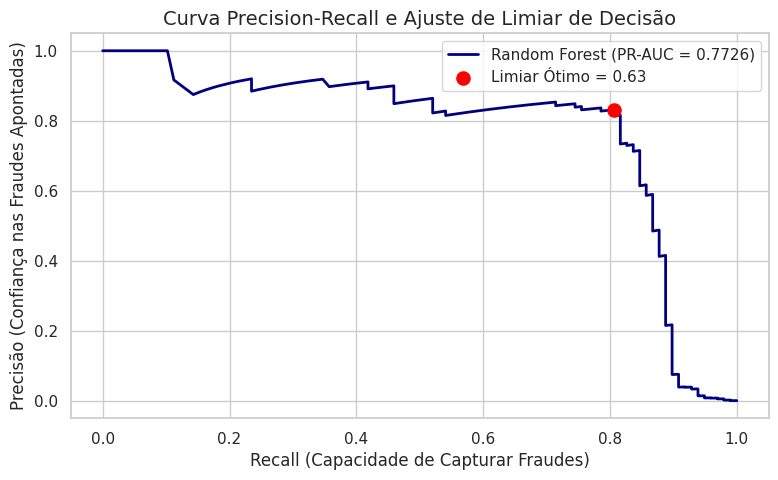


[5/5] Calculando explicabilidade com SHAP...


<Figure size 1000x600 with 0 Axes>

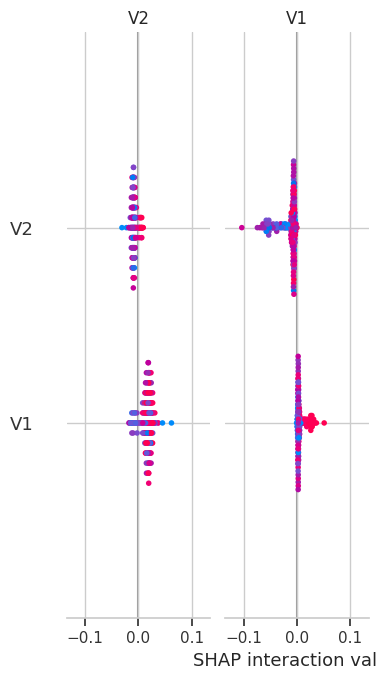


PROCESSO CONCLUÍDO COM SUCESSO! SEU NOTEBOOK ESTÁ PRONTO.


In [14]:
# ==============================================================================
# PIPELINE COMPLETO: DETECÇÃO DE ANOMALIAS EM TRANSAÇÕES (JORNADA TECH - DIO)
# ==============================================================================
# 1. INSTALAÇÃO DE PACOTES NECESSÁRIOS
!pip install xgboost shap -q
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)
import shap
# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
print("[1/5] Carregando a base de dados...")
# ------------------------------------------------------------------------------
# 2. CARREGAMENTO E EXPLORAÇÃO DOS DADOS (EDA)
# ------------------------------------------------------------------------------
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)
total = len(df)
fraudes = df['Class'].sum()
legitimas = total - fraudes
taxa_fraude = (fraudes / total) * 100
print(f"Total de Transações: {total:,}")
print(f"Transações Normais: {legitimas:,} ({(100 - taxa_fraude):.2f}%)")
print(f"Fraudes Confirmadas: {fraudes:,} ({taxa_fraude:.3f}%)")
print("\n[2/5] Realizando Engenharia de Features e Pré-processamento...")
# ------------------------------------------------------------------------------
# 3. ENGENHARIA DE FEATURES E PRÉ-PROCESSAMENTO
# ------------------------------------------------------------------------------
df_clean = df.copy()
# Log transform no valor para estabilizar outliers extremos
df_clean['Log_Amount'] = np.log1p(df_clean['Amount'])
# Padronização de escala para variáveis de tempo e valor
scaler = StandardScaler()
df_clean['Scaled_Time'] = scaler.fit_transform(df_clean[['Time']])
df_clean['Scaled_Amount'] = scaler.fit_transform(df_clean[['Log_Amount']])
# Separação de variáveis explicativas (X) e alvo (y)
X = df_clean.drop(columns=['Time', 'Amount', 'Log_Amount', 'Class'])
y = df_clean['Class']
# Divisão Treino (80%) e Teste (20%) com estratificação estrita
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Base de Treino: {len(X_train):,} registros ({y_train.sum()} fraudes)")
print(f"Base de Teste:  {len(X_test):,} registros ({y_test.sum()} fraudes)")
print("\n[3/5] Treinando os 3 modelos com pesos de balanceamento...")
# ------------------------------------------------------------------------------
# 4. TREINAMENTO DOS MODELOS COM BALANCEAMENTO
# ------------------------------------------------------------------------------
peso_fraude = (len(y_train) - y_train.sum()) / y_train.sum()
modelos = {
    "Regressão Logística (Baseline)": LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight='balanced', max_depth=8, n_jobs=-1, random_state=42
    ),
    "XGBoost": XGBClassifier(
        scale_pos_weight=peso_fraude, eval_metric="logloss", random_state=42
    )
}
predicoes = {}
probabilidades = {}
for nome, modelo in modelos.items():
    print(f"  -> Treinando {nome}...")
    modelo.fit(X_train, y_train)
    predicoes[nome] = modelo.predict(X_test)
    probabilidades[nome] = modelo.predict_proba(X_test)[:, 1]
print("\n[4/5] Avaliando métricas e curvas de performance...")
# ------------------------------------------------------------------------------
# 5. AVALIAÇÃO COMPARATIVA E CURVAS DE DECISÃO
# ------------------------------------------------------------------------------
tabela_metricas = []
for nome in modelos.keys():
    y_pred = predicoes[nome]
    y_prob = probabilidades[nome]

    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    pr_auc = average_precision_score(y_test, y_prob)
    roc_auc = roc_auc_score(y_test, y_prob)

    tabela_metricas.append({
        "Modelo": nome,
        "Recall (Detecção de Fraude)": f"{rec*100:.2f}%",
        "Precisão (Acertos)": f"{prec*100:.2f}%",
        "F1-Score": f"{f1:.4f}",
        "PR-AUC": f"{pr_auc:.4f}",
        "ROC-AUC": f"{roc_auc:.4f}"
    })
df_resumo = pd.DataFrame(tabela_metricas)
display(df_resumo)
# Gráfico da Curva Precision-Recall com Calibração de Limiar (Random Forest)
y_prob_rf = probabilidades["Random Forest"]
precisoes, recalls, limiares = precision_recall_curve(y_test, y_prob_rf)
f1_valores = 2 * (precisoes * recalls) / (precisoes + recalls + 1e-10)
melhor_idx = np.argmax(f1_valores)
melhor_limiar = limiares[melhor_idx] if melhor_idx < len(limiares) else 0.5
plt.figure(figsize=(9, 5))
plt.plot(recalls, precisoes, color='navy', lw=2, label=f"Random Forest (PR-AUC = {average_precision_score(y_test, y_prob_rf):.4f})")
plt.scatter(recalls[melhor_idx], precisoes[melhor_idx], color='red', s=90, zorder=5, label=f'Limiar Ótimo = {melhor_limiar:.2f}')
plt.title("Curva Precision-Recall e Ajuste de Limiar de Decisão", fontsize=14)
plt.xlabel("Recall (Capacidade de Capturar Fraudes)")
plt.ylabel("Precisão (Confiança nas Fraudes Apontadas)")
plt.legend()
plt.show()
print("\n[5/5] Calculando explicabilidade com SHAP...")
# ------------------------------------------------------------------------------
# 6. EXPLICABILIDADE COM SHAP (SHapley Additive exPlanations)
# ------------------------------------------------------------------------------
amostra = X_test.sample(n=200, random_state=42)
explainer = shap.TreeExplainer(modelos["Random Forest"])
shap_values = explainer.shap_values(amostra)
valores_fraude = shap_values[1] if isinstance(shap_values, list) else shap_values
plt.figure(figsize=(10, 6))
shap.summary_plot(valores_fraude, amostra, show=True)
print("\n" + "="*70)
print("PROCESSO CONCLUÍDO COM SUCESSO! SEU NOTEBOOK ESTÁ PRONTO.")
print("="*70)